# Higher-order dynamic correlations

This notebook covers the higher-order part of the toolbox, following Owen, Chang & Manning (2021), "High-level cognition during story listening is reflected in high-order dynamic correlations in neural activity patterns", *Nature Communications* 12, 5728 ([doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)):

1. the two paths of the paper's Fig. 10, and `tc.features`, which computes them;
2. features up to order 3;
3. one-sided kernels;
4. simulating data with structure at a chosen order, and recovering it;
5. the limits: how many features an order needs, the memory of unreduced runs, how much structure variance-based reduction (PCA) keeps when it exists only at order 2 or 3 (orders above 3 were not measured), and what `carrier_reducer` is for.

The estimator in version 0.3.0 differs from Eq. 4 of the paper (see the changelog), so the numbers here are not the paper's.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

import timecorr as tc
from timecorr.higher_order import estimate_memory_gb

%matplotlib inline
plt.rcParams['figure.dpi'] = 72
print(tc.__version__)

0.3.0


## 1. Two paths (Fig. 10)

Order 1 is the dynamic correlations of the data. Order `k` is the dynamic correlations of the order-`(k-1)` **co-fluctuations**: the moment-by-moment products of z-scored features, which `timecorr` returns for a delta kernel (`tc.eye_weights`). So each order has two paths:

- the **analysis path** `X_k = rfun(timecorr(D_{k-1}, analysis kernel, cfun, combine))` gives the order-`k` features;
- the **delta path** `D_k = delta_rfun(timecorr(D_{k-1}, eye_weights, cfun=autofc))` gives the co-fluctuations that feed order `k+1`.

`X_0 = D_0` is the data. Because the analysis kernel is applied only on the analysis path, each order's features are smoothed by it exactly once, not once per order.

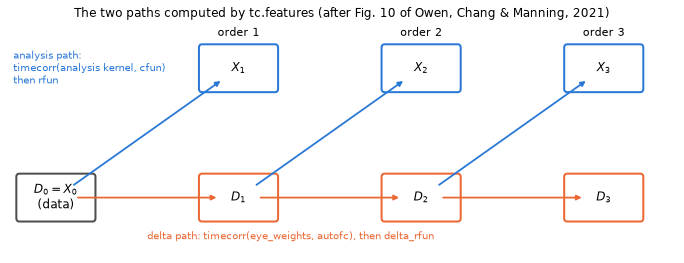

In [2]:
blue, orange = '#2a78d6', '#eb6834'
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.set_xlim(-0.8, 10.2)
ax.set_ylim(-0.9, 2.7)
ax.axis('off')

def box(x, y, text, color):
    ax.add_patch(FancyBboxPatch((x - 0.6, y - 0.32), 1.2, 0.64, boxstyle='round,pad=0.05',
                                fc='white', ec=color, lw=2))
    ax.text(x, y, text, ha='center', va='center', fontsize=12)

def arrow(x0, y0, x1, y1, color):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle='-|>', color=color, lw=1.8, shrinkA=22, shrinkB=22))

xs = [0, 3, 6, 9]
box(xs[0], 0, '$D_0 = X_0$\n(data)', '0.3')
for k in range(1, 4):
    box(xs[k], 2, f'$X_{k}$', blue)
    box(xs[k], 0, f'$D_{k}$', orange)
    arrow(xs[k - 1], 0, xs[k], 2, blue)
    arrow(xs[k - 1], 0, xs[k], 0, orange)
ax.text(-0.7, 2.0, 'analysis path:\ntimecorr(analysis kernel, cfun)\nthen rfun', color=blue,
        ha='left', va='center', fontsize=10)
ax.text(1.5, -0.6, 'delta path: timecorr(eye_weights, autofc), then delta_rfun', color=orange,
        ha='left', va='center', fontsize=10)
for k in range(1, 4):
    ax.text(xs[k], 2.5, f'order {k}', ha='center', fontsize=11)
ax.set_title('The two paths computed by tc.features (after Fig. 10 of Owen, Chang & Manning, 2021)')
plt.show()

## 2. Features up to order 3

`tc.features(data, order=n)` returns `[X_0, ..., X_n]`. By default (`rfun='PCA'`) every order is reduced to `K` columns, using one model fit jointly to all subjects. With `rfun=None` nothing is reduced and the width grows from `d` to `d(d+1)/2` at every order.

In [3]:
rng = np.random.default_rng(0)
T, K = 300, 6
data = rng.standard_normal((T, K))
kernel = {'weights_function': tc.gaussian_weights, 'weights_params': {'var': 100}}

X = tc.features(data, order=3, **kernel)
print('rfun="PCA":', [x.shape for x in X])

X_full, D_full = tc.features(data, order=3, rfun=None, return_delta=True, **kernel)
print('rfun=None: ', [x.shape for x in X_full])
print('delta path:', [d.shape for d in D_full])
print('estimated GB per order (rfun=None):', [round(g, 3) for g in estimate_memory_gb(K, 3, T)])

rfun="PCA": [(300, 6), (300, 6), (300, 6), (300, 6)]


rfun=None:  [(300, 6), (300, 21), (300, 231), (300, 26796)]
delta path: [(300, 6), (300, 21), (300, 231), (300, 26796)]
estimated GB per order (rfun=None): [0.0, 0.003, 0.01, 0.599]


For a list of subjects, `cfun` and `combine` act on the analysis path as in `timecorr` (the default `cfun` is `tc.isfc`); the delta path always uses each subject's own co-fluctuations (`autofc`) and is never combined across subjects.

In [4]:
subjects = [rng.standard_normal((T, K)) for _ in range(3)]
Xs = tc.features(subjects, order=2, cfun=tc.isfc, **kernel)
Xg = tc.features(subjects, order=2, cfun=tc.isfc, combine=tc.corrmean_combine, **kernel)
print('per subject:', [[x.shape for x in order] for order in Xs[1:]])
print('combined:   ', [x.shape for x in Xg[1:]])

per subject: [[(300, 6), (300, 6), (300, 6)], [(300, 6), (300, 6), (300, 6)]]
combined:    [(300, 6), (300, 6)]


## 3. One-sided kernels

Every kernel function takes `direction` (`'backward'`: only the current and past timepoints; `'forward'`: only the current and future timepoints) and `include_zero` (whether timepoint `t` itself contributes). `tc.one_sided` does the same to any kernel matrix. In `timecorr` and `tc.features` the same choices are made with `include_timepoints='backward'` / `'forward'` and `include_zero`.

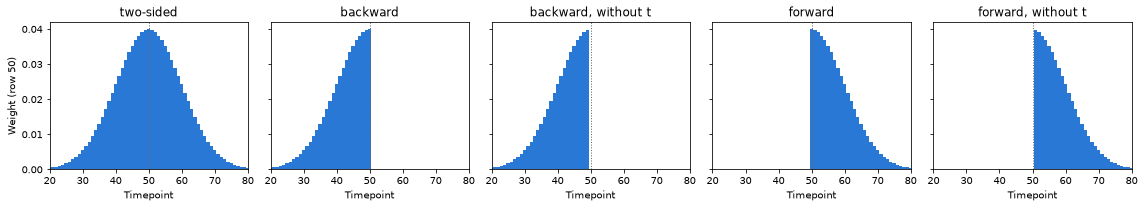

In [5]:
T1, t0 = 100, 50
variants = {
    'two-sided': {},
    'backward': {'direction': 'backward'},
    'backward, without t': {'direction': 'backward', 'include_zero': False},
    'forward': {'direction': 'forward'},
    'forward, without t': {'direction': 'forward', 'include_zero': False},
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, (name, kw) in zip(axes, variants.items()):
    w = tc.gaussian_weights(T1, {'var': 100}, **kw)[t0]
    ax.bar(np.arange(T1), w, width=1, color=blue)
    ax.axvline(t0, color='0.4', ls=':', lw=1)
    ax.set_xlim(t0 - 30, t0 + 30)
    ax.set_title(name)
    ax.set_xlabel('Timepoint')
axes[0].set_ylabel(f'Weight (row {t0})')
fig.tight_layout()
plt.show()

Applied to block data, a backward kernel uses only the past, so its estimates change after an event boundary; a forward kernel uses only the future, so they change before it. Near the edges a one-sided kernel row has fewer than 3 non-zero weights (a backward kernel at the first 2 timepoints, or the first 3 without `t`; a forward kernel at the last 2). Those rows are undefined: `timecorr` sets them to 0 and warns once per call. The cell below records and prints those warnings.

backward: 2 of 300 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
forward: 2 of 300 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
backward, without t: 3 of 300 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.


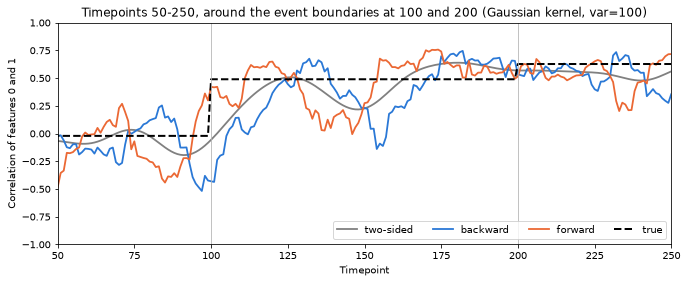

In [6]:
blk, blk_corrs = tc.simulate_data(datagen='block', T=300, K=6, B=3, return_corrs=True, set_random_seed=3)
gauss100 = {'weights_function': tc.gaussian_weights, 'weights_params': {'var': 100}}
settings = {'two-sided': {},
            'backward': {'include_timepoints': 'backward'},
            'forward': {'include_timepoints': 'forward'},
            'backward, without t': {'include_timepoints': 'backward', 'include_zero': False}}
est = {}
for name, kw in settings.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        est[name] = tc.timecorr(blk, **kw, **gauss100)
    for w in caught:
        print(f'{name}: {w.message}')

i, j = 0, 1
fig, ax = plt.subplots(figsize=(11, 4))
for name, color in zip(['two-sided', 'backward', 'forward'], ['0.5', blue, orange]):
    ax.plot(tc.vec2mat(est[name])[i, j], color=color, lw=1.8, label=name)
ax.plot(tc.vec2mat(blk_corrs)[i, j], color='k', ls='--', lw=2, label='true')
for b in (100, 200):
    ax.axvline(b, color='0.7', lw=0.8)
ax.set_xlabel('Timepoint')
ax.set_ylabel(f'Correlation of features {i} and {j}')
ax.set_xlim(50, 250)
ax.set_ylim(-1, 1)
ax.set_title('Timepoints 50-250, around the event boundaries at 100 and 200 (Gaussian kernel, var=100)')
ax.legend(ncol=4, loc='lower right')
plt.show()

## 4. Structure at a chosen order

`tc.simulate_data(order=n)` embeds a `p x p` template at exactly order `n`. The `K = p * 2**(n-1)` features form `p` blocks of `2**(n-1)` columns. Only the product of all of a block's columns (its **carrier**) follows the template; products of fewer columns have mean zero, so the orders below `n` hold no structure. With `return_corrs=True` and `order > 1` the ground truth comes back as a dict (for `order=1`, as the template array, as in the other tutorials):

In [7]:
data2, truth2 = tc.simulate_data(datagen='block', K=8, T=600, B=4, order=2,
                                 return_corrs=True, set_random_seed=0)
print(data2.shape, sorted(truth2))
print('blocks (column indices):', truth2['blocks'].tolist())
print('template shape:', truth2['corrs'].shape, '(timepoints, p(p+1)/2) with p = 4')

(600, 8) ['blocks', 'corrs', 'order', 'requested']
blocks (column indices): [[0, 1], [2, 3], [4, 5], [6, 7]]
template shape: (600, 10) (timepoints, p(p+1)/2) with p = 4


For order 2 the carrier of block `j` is the product of its two columns. Its order-1 correlations are those of the raw columns, which carry nothing; its order-2 correlations follow the template:

In [8]:
p = 4
kernel625 = {'weights_function': tc.gaussian_weights, 'weights_params': {'var': 625}, 'cfun': tc.autofc}
blocks2 = truth2['blocks']
X2 = tc.features(data2, order=2, rfun=None, delta_rfun=tc.carrier_reducer(blocks2), **kernel625)

def pooled_r(X, cols, corrs):
    # pooled r between the estimated p x p off-diagonal entries (columns cols of X's matrices) and the truth
    est = tc.vec2mat(X)[np.ix_(cols, cols, np.arange(X.shape[0]))]
    return np.corrcoef(tc.mat2vec(est)[:, p:].ravel(), corrs[:, p:].ravel())[0, 1]

print(f'order 1, first column of each block: r = {pooled_r(X2[1], blocks2[:, 0], truth2["corrs"]):.2f}')
print(f'order 2, block carriers:            r = {pooled_r(X2[2], np.arange(p), truth2["corrs"]):.2f}')

order 1, first column of each block: r = 0.02
order 2, block carriers:            r = 0.91


`carrier_reducer(blocks)` (section 5) keeps only the carriers on the delta path, so at order 2 the first `p` columns are the carriers. The next cell repeats this for embedded orders 1 to 4 over five seeds, and scores every analyzed order `k <= n` (at order `k < n` it scores the first carrier of each block). This is the same computation as the gallery example *Recover structure at a chosen order*.

In [9]:
T4, orders, seeds = 1000, [1, 2, 3, 4], [0, 1, 2, 3, 4]

def first_carriers(blocks, k, n):
    if k == 1:
        return np.asarray(blocks)[:, 0]
    return np.arange(p) * (2 ** (n - 1) // 2 ** (k - 1))

r = {n: np.full((n, len(seeds)), np.nan) for n in orders}
for s, seed in enumerate(seeds):
    for n in orders:
        with warnings.catch_warnings():
            # for n >= 3 simulate_data warns that PCA cannot keep this structure (section 5);
            # carrier_reducer is used instead
            warnings.filterwarnings('ignore', message='The simulated structure')
            d, truth = tc.simulate_data(datagen='block', K=p * 2 ** (n - 1), T=T4, B=4, order=n,
                                        return_corrs=True, set_random_seed=seed)
        if n == 1:
            corrs, blocks = truth, np.arange(p)[:, None]
            Xn = tc.features(d, order=1, rfun=None, **kernel625)
        else:
            corrs, blocks = truth['corrs'], truth['blocks']
            Xn = tc.features(d, order=n, rfun=None, delta_rfun=tc.carrier_reducer(blocks), **kernel625)
        for k in range(1, n + 1):
            r[n][k - 1, s] = pooled_r(Xn[k], first_carriers(blocks, k, n), corrs)

for n in orders:
    print(f'embedded at order {n}: mean r by analyzed order', np.round(r[n].mean(axis=1), 2))

embedded at order 1: mean r by analyzed order [0.93]
embedded at order 2: mean r by analyzed order [-0.04  0.93]
embedded at order 3: mean r by analyzed order [0.03 0.03 0.93]
embedded at order 4: mean r by analyzed order [-0.05 -0.08 -0.04  0.93]


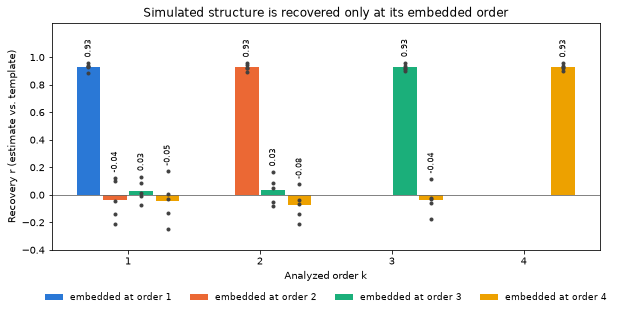

In [10]:
colors = [blue, orange, '#1baf7a', '#eda100']
width = 0.2
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, n in enumerate(orders):
    x = np.arange(1, n + 1) + (i - 1.5) * width
    means = r[n].mean(axis=1)
    ax.bar(x, means, width * 0.9, color=colors[i], label=f'embedded at order {n}')
    for xi, row, m in zip(x, r[n], means):
        ax.plot(np.full(len(seeds), xi), row, 'o', ms=3, color='0.25', zorder=3)
        ax.annotate(f'{m:.2f}', (xi, max(row.max(), 0) + 0.04), ha='center', va='bottom', rotation=90,
                    fontsize=8, bbox=dict(fc='white', ec='none', pad=0.5))
ax.axhline(0, color='0.4', lw=0.8)
ax.set_xticks(orders)
ax.set_xlabel('Analyzed order k')
ax.set_ylabel('Recovery r (estimate vs. template)')
ax.set_ylim(-0.4, 1.25)
ax.set_yticks(np.arange(-0.4, 1.01, 0.2))
ax.set_title('Simulated structure is recovered only at its embedded order')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 5. Limits

### Features needed

Embedding a `p x p` template at order `n` takes `p * 2**(n-1)` features (`tc.min_features`); `simulate_data` raises a `ValueError` for any other `K`.

In [11]:
print('order:        ', [1, 2, 3, 4, 5])
for pp in (3, 4):
    print(f'p = {pp} needs K =', [tc.min_features(n, p=pp) for n in range(1, 6)])

order:         [1, 2, 3, 4, 5]
p = 3 needs K = [3, 6, 12, 24, 48]
p = 4 needs K = [4, 8, 16, 32, 64]


### Memory of unreduced runs

Without reduction the width goes from `d` to `d(d+1)/2` at each order, and the correlation step at order `k` allocates a `(d, d, T)` array and holds every subject's `(T, d(d+1)/2)` results, besides the `T x T` kernels and fixed-size block temporaries. `estimate_memory_gb(K, order, T, n_subjects)` gives the estimated peak of each order for all subjects together, and `tc.features` raises a `MemoryError` before allocating anything when a step would exceed `max_memory_gb` (default 4). The error message gives the largest `K` that fits.

In [12]:
print('K=8, T=1000, GB by order:', [round(g, 3) for g in estimate_memory_gb(8, 3, 1000)])
try:
    tc.features(np.zeros((1000, 8)), order=3, rfun=None)
except MemoryError as err:
    print('MemoryError:', err)

K=8, T=1000, GB by order: [0.0, 0.028, 0.103, 5.749]
MemoryError: Unreduced features at order 3 need about 5.75 GB (K=8, T=1000, 1 subject), more than max_memory_gb=4.0. The largest number of features that fits orders up to 3 is K=7. Pass a reducer (rfun, delta_rfun), lower the order, or raise max_memory_gb.


### Variance-based reduction (PCA)

PCA (the default `rfun`) keeps the directions of largest variance among its input columns. On the delta path at order 1 the input is the pairwise co-fluctuations `D_1`.

- With structure at order 2, the carriers *are* columns of `D_1`, and the time-averaged template appears as correlations among them, so it contributes to the variance PCA ranks columns by.
- With structure at order 3, the carriers are products of pairs of `D_1` columns. Every `D_1` column has variance near 1 and the template leaves no trace in their correlations, so nothing distinguishes the columns PCA would need to keep. PCA's components then mix columns, and the products formed at the next order are products of mixtures, not the carriers.

The next cell measures the first point: the largest static correlation between two carrier columns of `D_1`, compared with the largest between any two `D_1` columns.

In [13]:
for n in (2, 3):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='The simulated structure')
        d, truth = tc.simulate_data(datagen='block', K=p * 2 ** (n - 1), T=600, B=4, order=n,
                                    return_corrs=True, set_random_seed=0)
    Kn = d.shape[1]
    D1 = tc.timecorr(d, weights_function=tc.eye_weights, weights_params={}, cfun=tc.autofc)[:, Kn:]
    C = np.corrcoef(D1.T)
    np.fill_diagonal(C, 0)
    level1 = np.asarray(tc.carrier_columns(truth['blocks'], 1, Kn)).ravel() - Kn  # off-diagonal positions
    print(f'order {n}: {len(level1)} carrier columns among {D1.shape[1]}; '
          f'max |r| between carriers {np.abs(C[np.ix_(level1, level1)]).max():.2f}, '
          f'between any two columns {np.abs(C).max():.2f}')

order 2: 4 carrier columns among 28; max |r| between carriers 0.27, between any two columns 0.27
order 3: 8 carrier columns among 120; max |r| between carriers 0.09, between any two columns 0.16


Whether the structure survives is measured with a score that needs no carrier columns. For block data (4 events), the order-`n` features at two timepoints are compared by their correlation across features. At each lag (distance in timepoints), the mean similarity of pairs in different events is subtracted from the mean similarity of pairs in the same event; the **event contrast** is the average of these differences over all lags that have both kinds of pair. Comparing at equal lags matters because the kernel makes nearby timepoints similar whatever the data.

The score is computed for structure embedded at order 2 and at order 3 (20 seeds each), with the delta path reduced by `carrier_reducer` (and `rfun=None`) or by PCA (`rfun='PCA'` on both paths, default number of dimensions). Each reducer is also applied to independent Gaussian noise of the same shape, scored the same way, as its control.

In [14]:
from scipy import stats

T3, B3 = 600, 4
event = np.repeat(np.arange(B3), T3 // B3)

def event_contrast(X):
    X = np.asarray(X, dtype=float)
    S = np.corrcoef(X[:, X.std(axis=0) > 0])  # timepoint-by-timepoint similarity
    diffs = []
    for L in range(1, T3):
        i = np.arange(T3 - L)
        s, same = S[i, i + L], event[i] == event[i + L]
        if same.any() and (~same).any():
            diffs.append(s[same].mean() - s[~same].mean())
    return np.mean(diffs)

contrast_seeds = range(20)
table = {}
for n in (2, 3):
    rows = {'carrier_reducer': [], 'carrier_reducer, noise': [], 'PCA': [], 'PCA, noise': []}
    for seed in contrast_seeds:
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='The simulated structure')
            d, truth = tc.simulate_data(datagen='block', K=p * 2 ** (n - 1), T=T3, B=B3, order=n,
                                        return_corrs=True, set_random_seed=seed)
        noise = np.random.default_rng(100 + seed).standard_normal(d.shape)
        carriers = tc.carrier_reducer(truth['blocks'])
        for name, x in [('', d), (', noise', noise)]:
            rows['carrier_reducer' + name].append(event_contrast(
                tc.features(x, order=n, rfun=None, delta_rfun=carriers, **kernel625)[n]))
            rows['PCA' + name].append(event_contrast(tc.features(x, order=n, rfun='PCA', **kernel625)[n]))
    table[n] = rows
    for name, v in rows.items():
        print(f'order {n}  {name:24s} mean {np.mean(v):6.2f}   range [{np.min(v):5.2f}, {np.max(v):5.2f}]')
    welch = stats.ttest_ind(rows['PCA'], rows['PCA, noise'], equal_var=False)
    print(f'order {n}  PCA vs its noise control: Welch t = {welch.statistic:.2f}, p = {welch.pvalue:.3f}')

order 2  carrier_reducer          mean   0.47   range [ 0.26,  0.94]
order 2  carrier_reducer, noise   mean   0.00   range [-0.20,  0.20]
order 2  PCA                      mean   0.21   range [-0.03,  0.47]
order 2  PCA, noise               mean   0.08   range [-0.17,  0.24]
order 2  PCA vs its noise control: Welch t = 3.08, p = 0.004


order 3  carrier_reducer          mean   0.48   range [ 0.29,  0.90]
order 3  carrier_reducer, noise   mean   0.03   range [-0.28,  0.39]
order 3  PCA                      mean  -0.00   range [-0.11,  0.11]
order 3  PCA, noise               mean   0.02   range [-0.10,  0.13]
order 3  PCA vs its noise control: Welch t = -1.31, p = 0.200


With `carrier_reducer` the events are clearly separated at both orders (mean contrast 0.47 at order 2 and 0.48 at order 3; noise controls 0.00 and 0.03). With PCA:

- **order 2**: part of the structure is kept. The contrast is 0.21, above its noise control (0.08; Welch p = 0.004) but well below the 0.47 obtained with `carrier_reducer`.
- **order 3**: PCA's contrast was not distinguishable from its noise control (-0.00 versus 0.02; Welch p = 0.20, 20 seeds).

Orders above 3 were not measured. For this reason `simulate_data(order=n)` warns for `n >= 3`. The alternatives are `rfun=None` (exact, but limited by memory) and, for simulated data, `carrier_reducer`.

### `carrier_reducer`

`tc.carrier_reducer(truth['blocks'])` builds a delta-path reducer for data from `simulate_data(order=n)`. At each order it keeps only the products of adjacent pairs of the previous order's carriers, block by block, so for `k < n` the delta path at order `k` has `p * 2**(n-1) / 2**k` columns, and the cost grows linearly with `K`. At order `n` each block has one carrier, and the analysis path gives the `p x p` correlation matrix among the carriers. Pass it as `delta_rfun`, with `rfun=None`. It uses the known block layout, so it applies to simulated data only; it is a way to test the pipeline at orders that unreduced runs cannot reach.

In [15]:
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='The simulated structure')  # the PCA warning above
    d4, truth4 = tc.simulate_data(datagen='block', K=32, T=300, B=4, order=4,
                                  return_corrs=True, set_random_seed=0)
X4, D4 = tc.features(d4, order=4, rfun=None, delta_rfun=tc.carrier_reducer(truth4['blocks']),
                     return_delta=True, **kernel625)
print('delta path widths:   ', [x.shape[1] for x in D4])
print('analysis path widths:', [x.shape[1] for x in X4])
print('unreduced GB by order for K=32, T=300:', [f'{g:.2e}' for g in estimate_memory_gb(32, 4, 300)])

delta path widths:    [32, 16, 8, 4, 10]
analysis path widths: [32, 528, 136, 36, 10]
unreduced GB by order for K=32, T=300: ['0.00e+00', '2.09e-02', '1.41e+00', '9.36e+04', '3.42e+14']


## Summary

- `tc.features` computes orders 0 to `n` with the two paths of Fig. 10: the analysis path gives the features, the delta path (co-fluctuations from `eye_weights`) feeds the next order.
- Kernels can be restricted to the past or the future (`direction`, `include_zero`, `tc.one_sided`, `include_timepoints`).
- `simulate_data(order=n)` embeds a template at exactly order `n`; it is recovered at order `n` and not below.
- An order-`n` template needs `p * 2**(n-1)` features; unreduced runs grow quickly in memory and are guarded by `max_memory_gb`; PCA keeps part of structure embedded at order 2, and at order 3 its contrast was not distinguishable from its noise control (orders above 3 were not measured); `carrier_reducer` keeps the structure for simulated data.

Reference: Owen, L. L. W., Chang, T. H. & Manning, J. R. High-level cognition during story listening is reflected in high-order dynamic correlations in neural activity patterns. *Nature Communications* 12, 5728 (2021). [doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)